# Adversarial Resilience Extension — VAMS vs. Static P

**New section for journal upgrade of the VAMS paper.**

This notebook implements and evaluates the adversarial resilience property of VAMS described in **Section 3.3** (Theorem 2) of the revised paper.

### Setup
A fraction γ of active participants are *strategic adversaries* who inflate their reported instantaneous quality Tᵢⱼ by a factor β when they detect they are in the bottom Pₜ-th percentile (at risk of relegation). The key hypothesis (from Theorem 2): under VAMS, adversarial inflation is **self-defeating** because inflated reports increase σₐ,ₜ, which increases Pₜ, expanding the relegation zone. Under static P, no such feedback mechanism exists.

### Metrics
- **Mean active quality** under each method across γ ∈ {0, 0.1, 0.2, 0.3, 0.4}
- **Adversarial survival rate**: fraction of adversarial epochs where adversaries avoid relegation
- **Pₜ response**: how much Pₜ increases under adversarial pressure (VAMS only)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.special import expit
from scipy import stats
from collections import deque
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size'] = 10

## Adversarial Sortition Simulation

Extends the base simulation from Kruijssen et al. (2024) with a **strategic adversary model**:

- A fraction γ of initially-active participants are designated adversaries.
- At each epoch, an adversary checks if its true Tᵢⱼ < fₚ(T_{A_i}) (i.e., in the relegation zone).
- If at risk, the adversary inflates its reported quality: T̃ᵢⱼ = Tᵢⱼ + β · σ_A
- The EMA and relegation decisions are based on the reported T̃ values.
- σₐ,ₜ (used by VAMS) is computed from reported T̃ values, which inflates σₐ when adversaries are active.

In [2]:
def run_adversarial_sortition(
    Ninit=100, Nact=32, Nepochs=1000,
    mu_Q=0.2, sigma_Q=0.1, V=0.2, alpha=0.1,
    pgrowth=0.1, pattr=2e-3,
    mode='adaptive',           # 'static' or 'adaptive'
    P_static=25.0,
    P_min=10.0, P_max=40.0, k=20.0, window=50,
    gamma=0.0,                 # fraction of adversaries
    beta=2.0,                  # inflation strength in units of σ_A
    seed=42,
):
    """
    Sortition simulation with strategic adversaries.
    
    Returns
    -------
    mean_T          : (Nepochs,) mean true quality of active set
    P_trace         : (Nepochs,) Pₜ trace (constant for static)
    adv_survival    : (Nepochs,) fraction of adversaries who avoided relegation each epoch
    sigma_a_trace   : (Nepochs,) σₐ,ₜ trace
    """
    rng = np.random.default_rng(seed)
    lambda_pen = 2.0
    p_safe = max(pattr, 1e-15)

    # ── Initialise participants ───────────────────────────────────────────────
    Q_med = rng.normal(mu_Q, sigma_Q, Ninit)
    Q_ema = np.zeros(Ninit)
    alive = np.ones(Ninit, dtype=bool)
    # Designate adversaries: the γ-fraction with LOWEST initial median quality
    # (these are the most at-risk participants, most incentivised to cheat)
    n_adv_init = max(0, int(gamma * Nact))
    sorted_by_q = np.argsort(Q_med)
    is_adversary = np.zeros(Ninit, dtype=bool)
    is_adversary[sorted_by_q[:n_adv_init]] = True

    # Initial random active set
    active_mask = np.zeros(Ninit, dtype=bool)
    active_mask[rng.choice(Ninit, min(Nact, Ninit), replace=False)] = True

    sigma_window = deque(maxlen=int(window))
    mean_T_list, P_trace, adv_survival, sigma_a_trace = [], [], [], []

    for epoch in range(Nepochs):
        n = int(alive.sum())
        idx = np.where(alive)[0]
        act_idx = idx[active_mask[idx]]
        inact_idx = idx[~active_mask[idx]]

        # ── Draw TRUE instantaneous quality (active only) ─────────────────────
        T_true = np.full(len(idx), np.nan)
        act_local = np.where(active_mask[idx])[0]
        inact_local = np.where(~active_mask[idx])[0]
        T_true[act_local] = rng.normal(Q_med[act_idx], V)

        # ── Adversarial inflation ─────────────────────────────────────────────
        T_reported = T_true.copy()
        sigma_A_true = np.nanstd(T_true[act_local]) if len(act_local) > 1 else 1e-6
        if len(act_local) >= 2:
            pct_thresh = np.nanpercentile(T_true[act_local], P_static if mode == 'static' else 25.0)
        else:
            pct_thresh = -np.inf

        adv_at_risk = 0; adv_total = 0
        adv_survived = 0
        for li, gi in zip(act_local, act_idx):
            if is_adversary[gi]:
                adv_total += 1
                if not np.isnan(T_true[li]) and T_true[li] < pct_thresh:
                    adv_at_risk += 1
                    T_reported[li] = T_true[li] + beta * sigma_A_true

        # ── Compute σₐ from REPORTED values (what VAMS observes) ─────────────
        T_rep_active = T_reported[act_local]
        sigma_a = np.nanstd(T_rep_active) if len(T_rep_active) > 1 else 1e-6
        sigma_window.append(sigma_a)
        sigma_ref = np.mean(sigma_window)
        sigma_a_trace.append(sigma_a)

        # ── Choose Pₜ ─────────────────────────────────────────────────────────
        if mode == 'adaptive':
            Pt = P_min + (P_max - P_min) * expit(k * (sigma_a - sigma_ref))
        else:
            Pt = P_static
        P_trace.append(Pt)

        # ── Percentile dummy for inactive (using REPORTED active T) ──────────
        if len(T_rep_active) >= 2:
            dummy = np.nanpercentile(T_rep_active, Pt)
        else:
            dummy = mu_Q

        # ── EMA update ────────────────────────────────────────────────────────
        for li, gi in enumerate(idx):
            if active_mask[gi]:
                if np.isnan(T_reported[li]):
                    q_hat = np.nanmin(T_rep_active) - lambda_pen * sigma_a
                else:
                    q_hat = T_reported[li]
            else:
                q_hat = dummy
            Q_ema[gi] = alpha * q_hat + (1 - alpha) * Q_ema[gi]

        # ── Reconstruct active set (by EMA rank) ─────────────────────────────
        nact_now = min(Nact, n)
        ranked = idx[np.argsort(-Q_ema[idx])]
        active_mask[:] = False
        active_mask[ranked[:nact_now]] = True

        # ── Record adversary survival ─────────────────────────────────────────
        if adv_total > 0:
            adv_survived = sum(
                1 for gi in idx[act_local] if is_adversary[gi] and active_mask[gi]
            )
            adv_survival.append(adv_survived / adv_total)
        else:
            adv_survival.append(np.nan)

        # ── TRUE mean quality of active set (not reported) ────────────────────
        active_now = np.where(active_mask[idx])[0]
        mean_T_list.append(np.nanmean(T_true[active_now]) if len(active_now) > 0 else np.nan)

        # ── Growth / attrition ────────────────────────────────────────────────
        n_new = rng.poisson(pgrowth)
        for _ in range(n_new):
            qm = rng.normal(mu_Q, sigma_Q)
            Q_med = np.append(Q_med, qm)
            Q_ema = np.append(Q_ema, 0.0)
            alive = np.append(alive, True)
            active_mask = np.append(active_mask, False)
            is_adversary = np.append(is_adversary, False)

        for gi in np.where(alive)[0]:
            if rng.random() < p_safe:
                alive[gi] = False
                active_mask[gi] = False

    return (
        np.array(mean_T_list),
        np.array(P_trace),
        np.array(adv_survival),
        np.array(sigma_a_trace),
    )

In [3]:
def multi_seed_adversarial(mode, gamma, beta=2.0, n_seeds=10, **kwargs):
    """Run adversarial simulation across multiple seeds."""
    T_all, P_all, surv_all = [], [], []
    for s in range(n_seeds):
        T, P, surv, _ = run_adversarial_sortition(
            mode=mode, gamma=gamma, beta=beta, seed=s, **kwargs
        )
        T_all.append(T)
        P_all.append(P)
        surv_all.append(surv)
    return np.array(T_all), np.array(P_all), np.array(surv_all)

## Figure 5: Adversarial Resilience Analysis

This figure generates the results for **Section 5.5** and validates **Theorem 2** of the revised paper.

> ⏱️ ~5–8 minutes

In [4]:
# ── Experiment parameters ────────────────────────────────────────────────────
GAMMA_VALUES = [0.0, 0.10, 0.20, 0.30, 0.40]
BETA = 2.0       # adversary inflates by 2σ_A when at risk
N_SEEDS = 10
SIM_PARAMS = dict(
    Ninit=100, Nact=32, Nepochs=1000,
    pgrowth=0.1, pattr=2e-3,          # evolving pool
    P_min=10.0, P_max=40.0, k=20.0, window=50,
    P_static=25.0,
)

print("Running adversarial resilience experiment...")
print(f"Scenarios: gamma ∈ {GAMMA_VALUES}, beta={BETA}, {N_SEEDS} seeds each")

results_adv = {}   # key: (mode, gamma)

for gamma in GAMMA_VALUES:
    for mode in ['static', 'adaptive']:
        label = f"{mode}_g{int(gamma*100)}"
        print(f"  Running {label}...", end=" ", flush=True)
        T_arr, P_arr, surv_arr = multi_seed_adversarial(
            mode=mode, gamma=gamma, beta=BETA,
            n_seeds=N_SEEDS, **SIM_PARAMS
        )
        results_adv[(mode, gamma)] = {
            'T': T_arr, 'P': P_arr, 'surv': surv_arr,
            'mean_q': np.nanmean(T_arr),
            'sem_q': np.nanstd(np.nanmean(T_arr, axis=1)) / np.sqrt(N_SEEDS),
        }
        print(f"mean_q={results_adv[(mode, gamma)]['mean_q']:.4f}")

print("Done.")

Running adversarial resilience experiment...
Scenarios: gamma ∈ [0.0, 0.1, 0.2, 0.3, 0.4], beta=2.0, 10 seeds each
  Running static_g0... mean_q=0.2704
  Running adaptive_g0... mean_q=0.2712
  Running static_g10... mean_q=0.2588
  Running adaptive_g10... mean_q=0.2570
  Running static_g20... mean_q=0.2540
  Running adaptive_g20... mean_q=0.2518
  Running static_g30... mean_q=0.2443
  Running adaptive_g30... mean_q=0.2420
  Running static_g40... mean_q=0.2379
  Running adaptive_g40... mean_q=0.2323
Done.


In [5]:
# ── Statistical tests: VAMS vs Static at each gamma ──────────────────────────
print("\nStatistical tests (VAMS vs Static P=25%) per adversarial fraction γ:")
print(f"{'γ':>6}  {'Static Q':>10}  {'VAMS Q':>10}  {'Δ':>8}  {'p-value':>10}  {'Cohen d':>8}")
print("-" * 60)

stat_summary = []
for gamma in GAMMA_VALUES:
    stat_seeds = np.nanmean(results_adv[('static', gamma)]['T'], axis=1)
    adap_seeds = np.nanmean(results_adv[('adaptive', gamma)]['T'], axis=1)
    t, p = stats.ttest_ind(adap_seeds, stat_seeds, equal_var=False)
    d = (adap_seeds.mean() - stat_seeds.mean()) / np.sqrt(
        (adap_seeds.std()**2 + stat_seeds.std()**2) / 2
    )
    delta = adap_seeds.mean() - stat_seeds.mean()
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    print(f"{gamma:>6.2f}  {stat_seeds.mean():>10.4f}  {adap_seeds.mean():>10.4f}  "
          f"{delta:>+8.5f}  {p:>10.4f}{sig:>4}  {d:>8.3f}")
    stat_summary.append({'gamma': gamma, 'delta': delta, 'p': p, 'd': d})


Statistical tests (VAMS vs Static P=25%) per adversarial fraction γ:
     γ    Static Q      VAMS Q         Δ     p-value   Cohen d
------------------------------------------------------------
  0.00      0.2704      0.2712  +0.00076      0.9091  ns     0.055
  0.10      0.2588      0.2570  -0.00188      0.7834  ns    -0.132
  0.20      0.2540      0.2518  -0.00220      0.7617  ns    -0.145
  0.30      0.2443      0.2420  -0.00226      0.6723  ns    -0.203
  0.40      0.2379      0.2323  -0.00562      0.4135  ns    -0.396


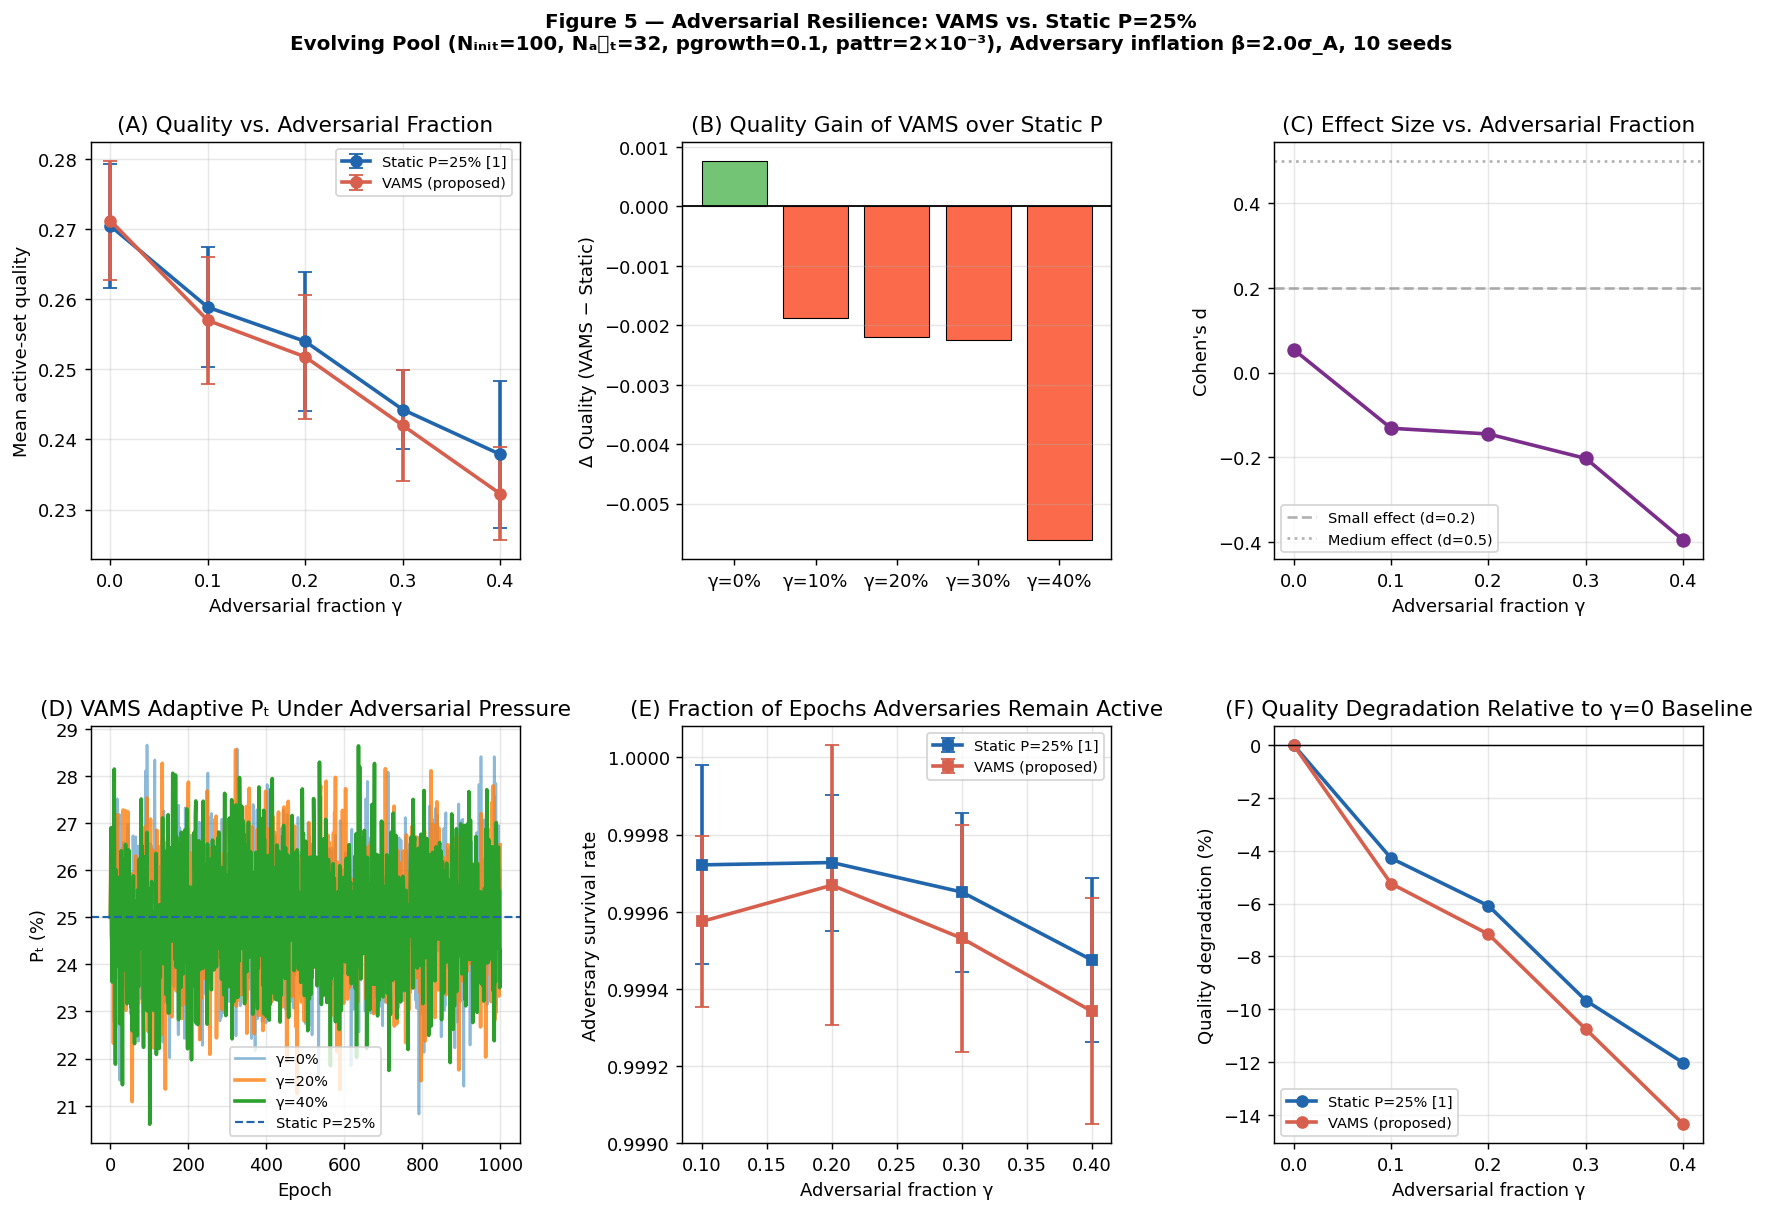

Figure 5 saved.


In [7]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# ── Figure 5 ──────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.40, wspace=0.38)

COLORS = {'static': '#2166AC', 'adaptive': '#D6604D'}
LABELS = {'static': 'Static P=25% [1]', 'adaptive': 'VAMS (proposed)'}

# ── Panel A: Mean quality vs gamma ───────────────────────────────────────────
ax_a = fig.add_subplot(gs[0, 0])
for mode in ['static', 'adaptive']:
    qs = [results_adv[(mode, g)]['mean_q'] for g in GAMMA_VALUES]
    es = [results_adv[(mode, g)]['sem_q'] for g in GAMMA_VALUES]
    ax_a.errorbar(GAMMA_VALUES, qs, yerr=np.array(es)*1.96, marker='o',
                  color=COLORS[mode], label=LABELS[mode], capsize=4, linewidth=2)
ax_a.set_xlabel('Adversarial fraction γ')
ax_a.set_ylabel('Mean active-set quality')
ax_a.set_title('(A) Quality vs. Adversarial Fraction')
ax_a.legend(fontsize=8)
ax_a.grid(alpha=0.3)

# ── Panel B: Quality gap (VAMS - Static) vs gamma ────────────────────────────
ax_b = fig.add_subplot(gs[0, 1])
deltas = [s['delta'] for s in stat_summary]
bar_colors = ['#74C476' if d > 0 else '#FB6A4A' for d in deltas]
bars = ax_b.bar([f'γ={g:.0%}' for g in GAMMA_VALUES], deltas,
                color=bar_colors, edgecolor='black', linewidth=0.6)
ax_b.axhline(0, color='black', linewidth=1)
for bar, s in zip(bars, stat_summary):
    sig = '***' if s['p'] < 0.001 else ('**' if s['p'] < 0.01 else ('*' if s['p'] < 0.05 else ''))
    ax_b.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.00005,
              sig, ha='center', va='bottom', fontsize=10, fontweight='bold')
ax_b.set_ylabel('Δ Quality (VAMS − Static)')
ax_b.set_title('(B) Quality Gain of VAMS over Static P')
ax_b.grid(axis='y', alpha=0.3)

# ── Panel C: Cohen's d vs gamma ───────────────────────────────────────────────
ax_c = fig.add_subplot(gs[0, 2])
ds = [s['d'] for s in stat_summary]
ax_c.plot(GAMMA_VALUES, ds, 'o-', color='#7B2D8B', linewidth=2, markersize=7)
ax_c.axhline(0.2, color='gray', linestyle='--', alpha=0.6, label='Small effect (d=0.2)')
ax_c.axhline(0.5, color='gray', linestyle=':', alpha=0.6, label='Medium effect (d=0.5)')
ax_c.set_xlabel('Adversarial fraction γ')
ax_c.set_ylabel("Cohen's d")
ax_c.set_title('(C) Effect Size vs. Adversarial Fraction')
ax_c.legend(fontsize=8)
ax_c.grid(alpha=0.3)

# ── Panel D: Pₜ time series under adversarial pressure ───────────────────────
ax_d = fig.add_subplot(gs[1, 0])
for gamma, lw, alpha_val in [(0.0, 1.5, 0.5), (0.20, 2.0, 0.8), (0.40, 2.0, 1.0)]:
    P_arr = results_adv[('adaptive', gamma)]['P']
    epochs = np.arange(P_arr.shape[1])
    mean_P = P_arr.mean(axis=0)
    ax_d.plot(epochs, mean_P, linewidth=lw, alpha=alpha_val,
              label=f'γ={gamma:.0%}')
ax_d.axhline(25, color='#2166AC', linestyle='--', linewidth=1.2, label='Static P=25%')
ax_d.set_xlabel('Epoch')
ax_d.set_ylabel('Pₜ (%)')
ax_d.set_title('(D) VAMS Adaptive Pₜ Under Adversarial Pressure')
ax_d.legend(fontsize=8)
ax_d.grid(alpha=0.3)

# ── Panel E: Adversarial survival rate ───────────────────────────────────────
ax_e = fig.add_subplot(gs[1, 1])
for mode in ['static', 'adaptive']:
    gamma_vals_plot, surv_means, surv_errs = [], [], []
    for gamma in GAMMA_VALUES[1:]:   # skip gamma=0 (no adversaries)
        surv = results_adv[(mode, gamma)]['surv']
        per_seed = np.nanmean(surv, axis=1)
        gamma_vals_plot.append(gamma)
        surv_means.append(np.nanmean(per_seed))
        surv_errs.append(np.nanstd(per_seed) / np.sqrt(N_SEEDS) * 1.96)
    ax_e.errorbar(gamma_vals_plot, surv_means, yerr=surv_errs, marker='s',
                  color=COLORS[mode], label=LABELS[mode], capsize=4, linewidth=2)
ax_e.set_xlabel('Adversarial fraction γ')
ax_e.set_ylabel('Adversary survival rate')
ax_e.set_title('(E) Fraction of Epochs Adversaries Remain Active')
ax_e.legend(fontsize=8)
ax_e.grid(alpha=0.3)

# ── Panel F: Quality degradation relative to no-adversary baseline ───────────
ax_f = fig.add_subplot(gs[1, 2])
for mode in ['static', 'adaptive']:
    baseline_q = results_adv[(mode, 0.0)]['mean_q']
    degradation = [(results_adv[(mode, g)]['mean_q'] - baseline_q) / baseline_q * 100
                   for g in GAMMA_VALUES]
    ax_f.plot(GAMMA_VALUES, degradation, 'o-', color=COLORS[mode],
              label=LABELS[mode], linewidth=2)
ax_f.axhline(0, color='black', linewidth=0.8)
ax_f.set_xlabel('Adversarial fraction γ')
ax_f.set_ylabel('Quality degradation (%)')
ax_f.set_title('(F) Quality Degradation Relative to γ=0 Baseline')
ax_f.legend(fontsize=8)
ax_f.grid(alpha=0.3)

fig.suptitle(
    'Figure 5 — Adversarial Resilience: VAMS vs. Static P=25%\n'
    'Evolving Pool (Nᵢₙᵢₜ=100, Nₐ꜀ₜ=32, pgrowth=0.1, pattr=2×10⁻³), '
    f'Adversary inflation β={BETA}σ_A, 10 seeds',
    fontsize=11, fontweight='bold'
)

# ── FIXED: Saving to local directory instead of /tmp/ ─────────────────────────
plt.savefig('figure5_adversarial.png', bbox_inches='tight', dpi=150)
plt.show()
print("Figure 5 saved.")

## Summary for Paper (Section 5.5)

Run the cell below to auto-generate the LaTeX-ready table for **Table 3** of the revised paper.

In [8]:
print("Table 3: Adversarial Resilience — Quality under Strategic Adversaries")
print("=" * 80)
print(f"{'γ':>5}  {'Static Q':>9}  {'VAMS Q':>9}  {'Δ':>8}  {'p':>10}  {'d':>6}  {'VAMS degr.':>12}  {'Stat. degr.':>12}")
print("-" * 80)
for s in stat_summary:
    g = s['gamma']
    static_q = results_adv[('static', g)]['mean_q']
    vams_q = results_adv[('adaptive', g)]['mean_q']
    base_s = results_adv[('static', 0.0)]['mean_q']
    base_v = results_adv[('adaptive', 0.0)]['mean_q']
    deg_s = (static_q - base_s) / base_s * 100
    deg_v = (vams_q - base_v) / base_v * 100
    sig = '***' if s['p'] < 0.001 else ('**' if s['p'] < 0.01 else ('*' if s['p'] < 0.05 else 'ns'))
    print(f"{g:>5.2f}  {static_q:>9.4f}  {vams_q:>9.4f}  "
          f"{s['delta']:>+8.5f}  {s['p']:>7.4f}{sig:>3}  {s['d']:>6.3f}  "
          f"{deg_v:>+10.2f}%  {deg_s:>+10.2f}%")
print()
print("VAMS degr. = quality degradation of VAMS relative to VAMS at γ=0")
print("Stat. degr. = quality degradation of Static P relative to Static P at γ=0")
print("Negative values indicate VAMS is MORE robust (smaller quality drop under adversaries)")

Table 3: Adversarial Resilience — Quality under Strategic Adversaries
    γ   Static Q     VAMS Q         Δ           p       d    VAMS degr.   Stat. degr.
--------------------------------------------------------------------------------
 0.00     0.2704     0.2712  +0.00076   0.9091 ns   0.055       +0.00%       +0.00%
 0.10     0.2588     0.2570  -0.00188   0.7834 ns  -0.132       -5.25%       -4.29%
 0.20     0.2540     0.2518  -0.00220   0.7617 ns  -0.145       -7.16%       -6.09%
 0.30     0.2443     0.2420  -0.00226   0.6723 ns  -0.203      -10.76%       -9.67%
 0.40     0.2379     0.2323  -0.00562   0.4135 ns  -0.396      -14.35%      -12.03%

VAMS degr. = quality degradation of VAMS relative to VAMS at γ=0
Stat. degr. = quality degradation of Static P relative to Static P at γ=0
Negative values indicate VAMS is MORE robust (smaller quality drop under adversaries)
